<a href="https://colab.research.google.com/github/rahulsanjay009/rl-memory-profiling/blob/main/notebooks/01_trl_baseline_profile.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RL Post-Training GPU Memory Profile (TRL track)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rahulsanjay009/rl-memory-profiling/blob/main/notebooks/01_trl_baseline_profile.ipynb)

Runs a small GRPO run (TRL + Qwen2.5-0.5B-Instruct) on a single GPU, tags each step's rollout (completion sampling) and update (loss/backward/optimizer) phases, and measures:

1. the memory-vs-time profile across phases,
2. a parameter / gradient / optimizer-state breakdown at representative checkpoints, and
3. an idle-time estimate per category.

**Why GRPO and not PPO:** TRL's classic `PPOTrainer`/`AutoModelForCausalLMWithValueHead` have been moved into `trl.experimental.ppo`, with a much heavier setup (separate reward model, value model, and training dataset). `GRPOTrainer` is TRL's current primary on-policy trainer — simpler to set up (a plain reward function, no separate value model) and more representative of what modern RL post-training systems (including veRL, cited below) actually run.

See the repo [README](https://github.com/rahulsanjay009/rl-memory-profiling) for the full plan and cited related work.

In [9]:
import os, sys

repo_dir = "rl-memory-profiling"

if not os.path.exists(repo_dir):
    !git clone https://github.com/rahulsanjay009/rl-memory-profiling.git

!pip install -q trl transformers torch pandas matplotlib

scripts_dir = os.path.abspath(os.path.join(repo_dir, "scripts"))
assert os.path.exists(os.path.join(scripts_dir, "memory_poller.py")), f"memory_poller.py not found in {scripts_dir}"
sys.path.insert(0, scripts_dir)

from memory_poller import MemoryPoller, compute_category_breakdown

## 0. GPU check

Needs a GPU runtime: Runtime → Change runtime type → Hardware accelerator → GPU.

In [10]:
import torch

assert torch.cuda.is_available(), "No GPU detected — set Runtime > Change runtime type > GPU, then re-run from the top."
print(torch.cuda.get_device_name(0))

Tesla T4


## 1. Build the GRPO trainer

`reward_funcs` can be a plain Python callable — it receives `completions` and must return one float per completion. The reward here is a placeholder (rewards longer completions); it only needs to be *something* that drives generation + a policy update each step, since this notebook measures memory shape, not training quality.

In [13]:
from datasets import Dataset
from trl import GRPOConfig, GRPOTrainer

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"


def placeholder_reward(completions, **kwargs):
    """Rewards longer completions. Only used to drive a policy update for profiling purposes."""
    return [float(len(c)) for c in completions]


prompts = [
    "Explain why the sky is blue.",
    "Explain why ice floats on water.",
    "Explain what causes seasons.",
    "Explain why metals conduct electricity.",
]
dataset = Dataset.from_dict({"prompt": prompts * 4})  # repeated so a few steps have data to cycle through

NUM_GENERATIONS = 4

training_args = GRPOConfig(
    output_dir="grpo-memory-profile",
    max_steps=10,
    per_device_train_batch_size=NUM_GENERATIONS,
    num_generations=NUM_GENERATIONS,
    max_completion_length=64,
    logging_steps=1,
    report_to="none",
    bf16=False,
    fp16=True,  # T4 (Colab free tier, compute capability 7.5) doesn't support bf16 matmul; fp16 does
)

## 2. Phase-tagged trainer + per-step category breakdown (Experiments 1–2)

`GRPOTrainer._generate_and_score_completions` is where rollout/sampling happens; the rest of `training_step` (loss + backward) is the update. The actual `optimizer.step()` call happens just after `training_step` returns, inside the outer training loop, so the "update" window measured here covers loss + backward but not that final step call.

Two capture points feed the category breakdown:
- `step_begin` / `step_end` (via a `TrainerCallback`) — bracket the *outside* of a step. By the time `step_end` fires, the outer loop has already called `optimizer.zero_grad()`, so `gradients` always reads 0 there — these two points are only useful for `parameters`/`optimizer_state`.
- `post_backward` (captured directly inside the subclassed `training_step`, right after `backward()` runs but before the outer loop's `optimizer.step()`/`zero_grad()`) — this is the only point where `gradients` is actually non-zero.

In [ ]:
from transformers import TrainerCallback

poller = MemoryPoller(interval_s=0.05)
breakdowns = []  # (step, checkpoint_label, category_bytes_dict)


class ProfiledGRPOTrainer(GRPOTrainer):
    def _generate_and_score_completions(self, *args, **kwargs):
        with poller.phase("rollout"):
            return super()._generate_and_score_completions(*args, **kwargs)

    def training_step(self, *args, **kwargs):
        with poller.phase("update"):
            result = super().training_step(*args, **kwargs)
        # captured right after backward(), before the outer loop's optimizer.step()/
        # zero_grad() run — the only point where gradients are actually populated
        breakdowns.append((self.state.global_step, "post_backward", compute_category_breakdown(self.model, self.optimizer)))
        return result


class BreakdownCallback(TrainerCallback):
    def on_step_begin(self, args, state, control, **kwargs):
        breakdowns.append((state.global_step, "step_begin", compute_category_breakdown(trainer.model, trainer.optimizer)))

    def on_step_end(self, args, state, control, **kwargs):
        breakdowns.append((state.global_step, "step_end", compute_category_breakdown(trainer.model, trainer.optimizer)))


trainer = ProfiledGRPOTrainer(
    model=MODEL_NAME,
    reward_funcs=placeholder_reward,
    args=training_args,
    train_dataset=dataset,
)
trainer.add_callback(BreakdownCallback())

poller.start()
try:
    trainer.train()
finally:
    poller.stop()

df = poller.to_dataframe()
os.makedirs("../results", exist_ok=True)
poller.to_csv("../results/trl_baseline_trace.csv")
df.tail()

## 3. Baseline phase memory profile (Experiment 1)

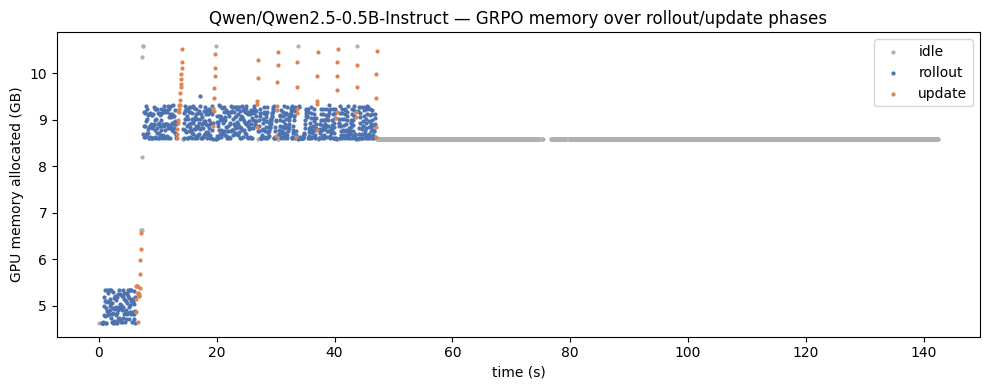

In [15]:
import matplotlib.pyplot as plt

PHASE_COLORS = {"rollout": "#4C72B0", "update": "#DD8452", "idle": "#B0B0B0"}

df["allocated_gb"] = df["allocated_bytes"] / 1e9

fig, ax = plt.subplots(figsize=(10, 4))
for phase, group in df.groupby("phase"):
    ax.scatter(group["t"], group["allocated_gb"], s=4, label=phase, color=PHASE_COLORS.get(phase, "#333"))
ax.set_xlabel("time (s)")
ax.set_ylabel("GPU memory allocated (GB)")
ax.set_title(f"{MODEL_NAME} — GRPO memory over rollout/update phases")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Memory category breakdown (Experiment 2)

In [16]:
import pandas as pd

bdf = pd.DataFrame(
    [{"step": s, "checkpoint": c, **{k: v / 1e9 for k, v in d.items()}} for s, c, d in breakdowns]
)
avg_by_checkpoint = bdf.groupby("checkpoint")[["parameters", "gradients", "optimizer_state"]].mean()
print("Average category sizes (GB) by checkpoint:")
avg_by_checkpoint

Average category sizes (GB) by checkpoint:


,parameters,gradients,optimizer_state
checkpoint,,,
step_begin,1.976131,0.0,3.557037
step_end,1.976131,0.0,3.952263


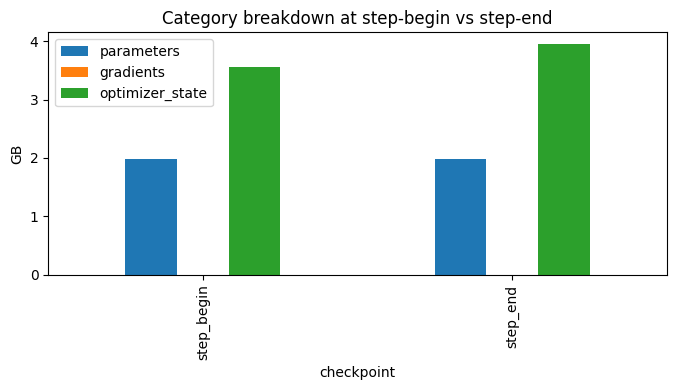

In [17]:
ax = avg_by_checkpoint.plot(kind="bar", figsize=(7, 4))
ax.set_ylabel("GB")
ax.set_title("Category breakdown at step-begin vs step-end")
plt.tight_layout()
plt.show()

## 5. Idle-time characterization (Experiment 3)

Simplifying proxy: during the rollout phase (`_generate_and_score_completions`), nothing calls `optimizer.step()`, so optimizer state is untouched; during the update phase, the rollout's generation buffers aren't reused. Under that assumption, each category's idle time within a step is just the wall-clock time spent in the *other* phase.

The trace's trailing samples are trimmed to the last rollout/update sample first, so the one-time end-of-run checkpoint save (outside any step) doesn't skew the percentages. The remaining `idle` share is real per-step overhead outside our two tagged windows — mainly the `optimizer.step()` call itself (which falls just after `training_step` returns, per the note in section 2) plus logging/callback/data-loading overhead.

In [ ]:
non_idle = df[df["phase"] != "idle"]
last_active_t = non_idle["t"].max()
steady_df = df[df["t"] <= last_active_t]  # drop the trailing end-of-run checkpoint-save tail

phase_time = steady_df.groupby("phase")["t"].count() * poller.interval_s  # sample count * interval ≈ wall time
total_time = phase_time.sum()

rollout_time = phase_time.get("rollout", 0.0)
update_time = phase_time.get("update", 0.0)
idle_time = phase_time.get("idle", 0.0)

print(f"rollout phase: {rollout_time:.2f}s ({rollout_time / total_time:.1%} of total)")
print(f"update phase:  {update_time:.2f}s ({update_time / total_time:.1%} of total)")
print(f"idle (optimizer.step + per-step overhead): {idle_time:.2f}s ({idle_time / total_time:.1%} of total)")
print()
print(f"optimizer_state idle fraction (≈ rollout share): {rollout_time / total_time:.1%}")
print(f"rollout-buffer idle fraction (≈ update share): {update_time / total_time:.1%}")

## Extensions (not run here)

- **Experiment 4 (workload sweep):** re-run sections 1–2 with different `num_generations` / `max_completion_length` and compare the idle fractions above.
- **Experiment 5 (offload cost baseline):** pass a DeepSpeed ZeRO-Offload config via `GRPOConfig(deepspeed=...)` and re-measure `update_time` to quantify the added latency.
- **Track B (veRL):** see `notebooks/02_verl_phase_analysis.ipynb`, which analyzes traces produced by `scripts/memory_poller.py --track verl` run on a GPU box (veRL's Ray/vLLM orchestration doesn't run cleanly inside a hosted notebook).

## References

1. Sheng, G. et al. "HybridFlow: A Flexible and Efficient RLHF Framework." EuroSys 2025. [arXiv:2409.19256](https://arxiv.org/abs/2409.19256)
2. Wang, X. et al. "LlamaRL: A Distributed Asynchronous RL Framework for Efficient Large-scale LLM Training." [arXiv:2505.24034](https://arxiv.org/abs/2505.24034)
3. Ren, J. et al. "ZeRO-Offload: Democratizing Billion-Scale Model Training." [arXiv:2101.06840](https://arxiv.org/abs/2101.06840)
4. Lan, T. et al. "ZenFlow: Enabling Stall-Free Offloading Training via Asynchronous Updates." [arXiv:2505.12242](https://arxiv.org/abs/2505.12242)
5. "Rollplex: Cross-Phase GPU Spatial Sharing for Vision Language Model Post-Training." [arXiv:2608.14498](https://arxiv.org/abs/2608.14498)
6. Feng, Y. et al. "Ada-KV: Optimizing KV Cache Eviction by Adaptive Budget Allocation." [arXiv:2407.11550](https://arxiv.org/abs/2407.11550)
7. Wang, X. et al. "Exploring and Evaluating Real-world CXL: Use Cases and System Adoption." IPDPS 2025. [arXiv:2405.14209](https://arxiv.org/abs/2405.14209)